In [28]:
import numpy as np
import pandas as pd
import machinegnostics

In [29]:
print(machinegnostics.__version__)

0.0.7


# Data Loading and Processing

In [30]:
# read file from the github link
# https://github.com/kamleshparmar17/Advanced_PulseHeatPipe_krp/blob/main/data/database/database.csv
url = "database.csv"
db = pd.read_csv(url)
db.head()

# save data 
db.to_csv("database.csv", index=False)

In [31]:
db.keys()

Index(['TIME', 'DATE', 'TC_1', 'TC_2', 'TC_3', 'TC_4', 'TC_5', 'TC_6', 'TC_7',
       'TC_8', 'TC_9', 'PRESSURE', 'HEATER', 'HEATER SET POINT', 'date',
       'voltage', 'current', 'power', 'WF', 'FR[%]', 'Q[W]', 'alpha', 'beta',
       'pulse', 'Te_mean[C]', 'Tc_mean[C]', 'Te_std[C]', 'Tc_std[C]', 'P[bar]',
       'Te_mean[K]', 'Tc_mean[K]', 'Te_std[K]', 'Tc_std[K]', 'T_pulse[K]',
       'TR[K/W]', 'GFE_Te[KJ/mol]', 'GFE_Tc[KJ/mol]', 'dG[KJ/mol]'],
      dtype='str')

In [32]:
drop_columns = ['TC_1', 'TC_2', 'TC_3', 'TC_4', 'TC_5', 'TC_6', 'TC_7',
       'TC_8', 'TC_9', 'GFE_Te[KJ/mol]', 'GFE_Tc[KJ/mol]', 'dG[KJ/mol]', 
       'TIME', 'DATE', 'date', 'voltage', 'current', 'HEATER', 'HEATER SET POINT', 'power',
       'pulse', 'Te_mean[C]', 'Tc_mean[C]', 'P[bar]',
       'Te_std[C]', 'Tc_std[C]', 'PRESSURE', 'Te_std[K]', 'Tc_std[K]', 'Tc_mean[K]']  # replace with actual column names

df = db.drop(columns=drop_columns)

# drop duplicate rows
df = df.drop_duplicates()
df.head()

,WF,FR[%],Q[W],alpha,beta,Te_mean[K],T_pulse[K],TR[K/W]
0,DI water,60,40,0,0,307.43,353.75,0.09
8,DI water,60,40,0,0,307.51,353.75,0.09
11,DI water,60,40,0,0,307.59,353.75,0.09
12,DI water,60,40,0,0,307.61,353.75,0.09
14,DI water,60,40,0,0,307.69,353.75,0.09


In [33]:
# applying filter for specific conditions
alpha = 0
df_Q40_DIW_a90_b0 = df[(df['Q[W]'] == 40) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]
df_Q60_DIW_a90_b0 = df[(df['Q[W]'] == 60) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]
df_Q80_DIW_a90_b0 = df[(df['Q[W]'] == 80) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]
df_Q100_DIW_a90_b0 = df[(df['Q[W]'] == 100) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]
df_Q120_DIW_a90_b0 = df[(df['Q[W]'] == 120) & (df['WF'] == 'DI water') & (df['alpha'] == alpha) & (df['beta'] == 0)]

In [34]:
# Te_mean[K] mean for each df
df_Q40_DIW_a90_b0_T_mean = df_Q40_DIW_a90_b0['Te_mean[K]'].median()
df_Q60_DIW_a90_b0_T_mean = df_Q60_DIW_a90_b0['Te_mean[K]'].median()
df_Q80_DIW_a90_b0_T_mean = df_Q80_DIW_a90_b0['Te_mean[K]'].median()
df_Q100_DIW_a90_b0_T_mean = df_Q100_DIW_a90_b0['Te_mean[K]'].median()
df_Q120_DIW_a90_b0_T_mean = df_Q120_DIW_a90_b0['Te_mean[K]'].median()
# print
print(df_Q40_DIW_a90_b0_T_mean)
print(df_Q60_DIW_a90_b0_T_mean)
print(df_Q80_DIW_a90_b0_T_mean)
print(df_Q100_DIW_a90_b0_T_mean)
print(df_Q120_DIW_a90_b0_T_mean)

338.38
355.21
367.47
359.25
369.37


In [35]:
# temperature filter for Te_mean[K] around t (350)
t= 351
t_1 = t + 2
temp = 'Te_mean[K]'
df_Q40_DIW_a90_b0_T =df_Q40_DIW_a90_b0[(df_Q40_DIW_a90_b0[temp] >= t) & (df_Q40_DIW_a90_b0[temp] <= t_1)].drop_duplicates()
df_Q60_DIW_a90_b0_T =df_Q60_DIW_a90_b0[(df_Q60_DIW_a90_b0[temp] >= t) & (df_Q60_DIW_a90_b0[temp] <= t_1)].drop_duplicates()
df_Q80_DIW_a90_b0_T =df_Q80_DIW_a90_b0[(df_Q80_DIW_a90_b0[temp] >= t) & (df_Q80_DIW_a90_b0[temp] <= t_1)].drop_duplicates()
df_Q100_DIW_a90_b0_T =df_Q100_DIW_a90_b0[(df_Q100_DIW_a90_b0[temp] >= t) & (df_Q100_DIW_a90_b0[temp] <= t_1)].drop_duplicates()
df_Q120_DIW_a90_b0_T =df_Q120_DIW_a90_b0[(df_Q120_DIW_a90_b0[temp] >= t) & (df_Q120_DIW_a90_b0[temp] <= t_1)].drop_duplicates()

In [36]:
# print average Te_mean[K] for filtered dataframes
print(df_Q40_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q60_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q80_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q100_DIW_a90_b0_T['Te_mean[K]'].mean())
print(df_Q120_DIW_a90_b0_T['Te_mean[K]'].mean())

352.0954054054055
352.11000000000007
352.0357142857143
351.878
351.706


In [37]:
# at t filter and get TR[K/W] values save df
df_Q40_DIW_a90_b0_T_TR = df_Q40_DIW_a90_b0_T[['TR[K/W]']]
df_Q60_DIW_a90_b0_T_TR = df_Q60_DIW_a90_b0_T[['TR[K/W]']]
df_Q80_DIW_a90_b0_T_TR = df_Q80_DIW_a90_b0_T[['TR[K/W]']]
df_Q100_DIW_a90_b0_T_TR = df_Q100_DIW_a90_b0_T[['TR[K/W]']]
df_Q120_DIW_a90_b0_T_TR = df_Q120_DIW_a90_b0_T[['TR[K/W]']]
print(df_Q40_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q60_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q80_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q100_DIW_a90_b0_T['TR[K/W]'].mean())
print(df_Q120_DIW_a90_b0_T['TR[K/W]'].mean())

1.208378378378378
0.8000000000000002
0.61
0.496
0.418


In [38]:
# print lengths of filtered dataframes
print(len(df_Q40_DIW_a90_b0_T))
print(len(df_Q60_DIW_a90_b0_T))
print(len(df_Q80_DIW_a90_b0_T))
print(len(df_Q100_DIW_a90_b0_T))
print(len(df_Q120_DIW_a90_b0_T))

37
14
7
10
5


# EU Calculation

In [39]:
# Expanded Uncertainty for TR[K/W] at filtered temperature with 95% confidence interval
import scipy.stats as stats
def expanded_uncertainty(df, confidence=0.95):
    n = len(df)
    mean = df['TR[K/W]'].mean()
    std_err = df['TR[K/W]'].std()
    t_value = stats.t.ppf((1 + confidence) / 2., n-1)
    std_err *= t_value
    return mean, std_err

print(expanded_uncertainty(df_Q40_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q60_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q80_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q100_DIW_a90_b0_T_TR))
print(expanded_uncertainty(df_Q120_DIW_a90_b0_T_TR))

(np.float64(1.208378378378378), np.float64(0.030048628342577283))
(np.float64(0.8000000000000002), np.float64(0.020756150669865817))
(np.float64(0.61), np.float64(0.019978951602914102))
(np.float64(0.496), np.float64(0.015817136321961637))
(np.float64(0.418), np.float64(0.012416639982037653))


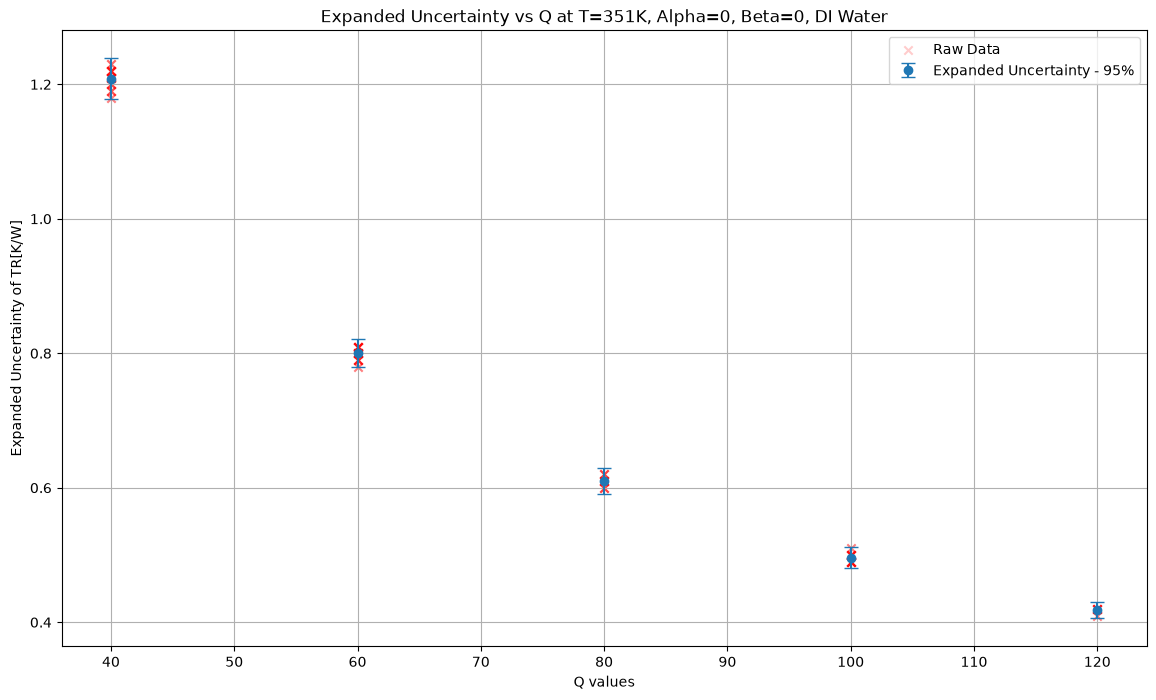

In [40]:
# plot expanded uncertainty for TR[K/W] at filtered temperature and Q
# X axis Q values and y axis expanded uncertainty of TR[K/W] errorbar

import matplotlib.pyplot as plt
Q_values = [40, 60, 80, 100, 120]

mean_Q40, expanded_Q40 = expanded_uncertainty(df_Q40_DIW_a90_b0_T_TR)
mean_Q60, expanded_Q60 = expanded_uncertainty(df_Q60_DIW_a90_b0_T_TR)
mean_Q80, expanded_Q80 = expanded_uncertainty(df_Q80_DIW_a90_b0_T_TR)
mean_Q100, expanded_Q100 = expanded_uncertainty(df_Q100_DIW_a90_b0_T_TR)
mean_Q120, expanded_Q120 = expanded_uncertainty(df_Q120_DIW_a90_b0_T_TR)

mean_values = [mean_Q40, mean_Q60, mean_Q80, mean_Q100, mean_Q120]
expanded_uncertainties = [expanded_Q40, expanded_Q60, expanded_Q80, expanded_Q100, expanded_Q120]

plt.figure(figsize=(14,8))
plt.errorbar(Q_values, mean_values, yerr=expanded_uncertainties, fmt='o', capsize=5, label='Expanded Uncertainty - 95%')
# plot raw data points for reference
plt.scatter([40]*len(df_Q40_DIW_a90_b0_T_TR), df_Q40_DIW_a90_b0_T_TR, color='red', alpha=0.2, label='Raw Data', marker='x')
plt.scatter([60]*len(df_Q60_DIW_a90_b0_T_TR), df_Q60_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([80]*len(df_Q80_DIW_a90_b0_T_TR), df_Q80_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([100]*len(df_Q100_DIW_a90_b0_T_TR), df_Q100_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([120]*len(df_Q120_DIW_a90_b0_T_TR), df_Q120_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.xlabel('Q values')
plt.ylabel('Expanded Uncertainty of TR[K/W]')
plt.title(f'Expanded Uncertainty vs Q at T={t}K, Alpha={alpha}, Beta=0, DI Water')
plt.legend()
plt.grid()
plt.show()


# Machine Gnostic EU calculations

In [41]:
from machinegnostics.magcal import IntervalAnalysis

In [42]:
engine_q40 = IntervalAnalysis(n_points=30)

intv_q40 =engine_q40.fit(data=df_Q40_DIW_a90_b0_T_TR.to_numpy().reshape(-1))

# engine_q40.plot()



In [43]:
engine_q60 = IntervalAnalysis(n_points=30)
intv_q60 = engine_q60.fit(data=df_Q60_DIW_a90_b0_T_TR.to_numpy().reshape(-1))

In [44]:

engine_q80 = IntervalAnalysis(n_points=30)
intv_q80 = engine_q80.fit(data=df_Q80_DIW_a90_b0_T_TR.to_numpy().reshape(-1))

In [45]:
engine_q100 = IntervalAnalysis(n_points=30)
intv_q100 = engine_q100.fit(data=df_Q100_DIW_a90_b0_T_TR.to_numpy().reshape(-1))


In [46]:
engine_q120 = IntervalAnalysis(n_points=30)
intv_q120 = engine_q120.fit(data=df_Q120_DIW_a90_b0_T_TR.to_numpy().reshape(-1))

# engine_q120.plot()

In [47]:
intv_q120

array({'LB': 0.405025900479283, 'LSB': 0.40974649988767414, 'DLB': 0.41, 'LCB': 0.41629, 'LSD': 0.41827787450506465, 'ZL': 0.41848659013513995, 'Z0L': 0.41987466863171025, 'Z0': 0.41997999999999996, 'Z0U': 0.42014543639788227, 'ZU': 0.4210858897792674, 'USD': 0.4217221254949353, 'UCB': 0.42, 'DUB': 0.42, 'USB': 0.4202535001123258, 'UB': 0.4250267725960598},
      dtype=object)

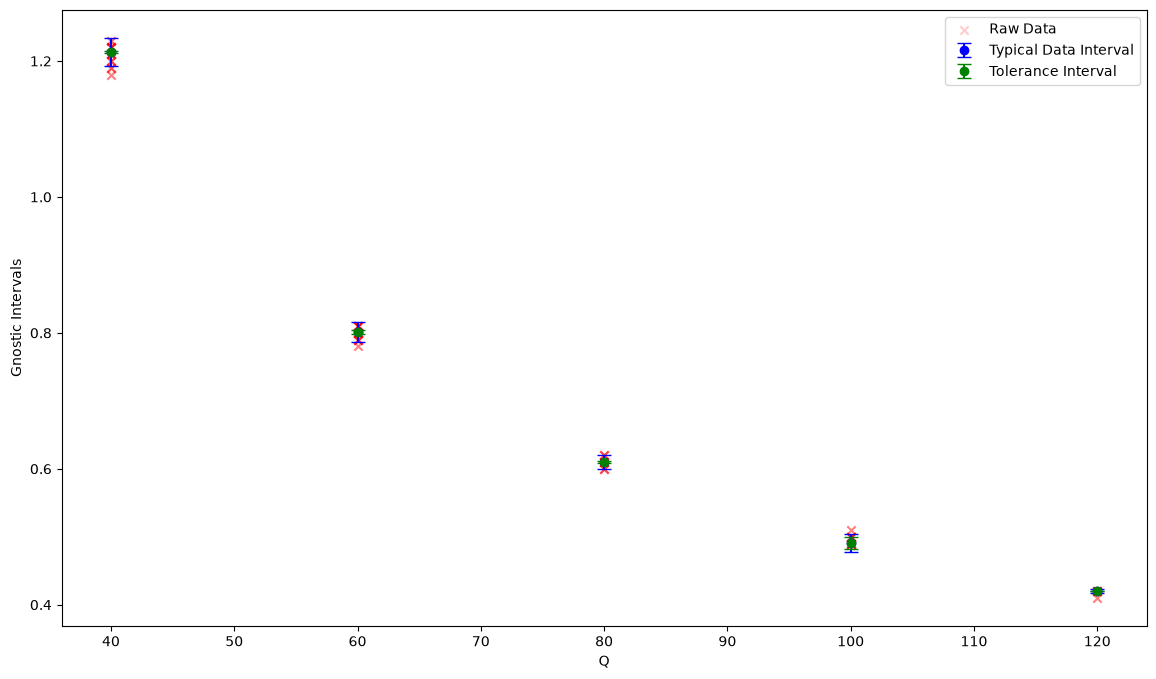

In [48]:
# plot intervals, x axis Q and y axis gnostic interval. mean, tolerance interval and typical data interval
import matplotlib.pyplot as plt

Q_values = [40, 60, 80, 100, 120]
intervals = [intv_q40, intv_q60, intv_q80, intv_q100, intv_q120]

plt.figure(figsize=(14, 8))
# plt.errorbar(Q_values, mean_values, yerr=expanded_uncertainties, fmt='o', capsize=5, label='Expanded Uncertainty - 95%')
# 40Q
plt.errorbar(40, intv_q40.item()['Z0'], 
             yerr=(intv_q40.item()['ZU'] - intv_q40.item()['ZL']),
             fmt='o', capsize=5, label='Typical Data Interval', color='blue')
plt.errorbar(40, intv_q40.item()['Z0'], 
             yerr=(intv_q40.item()['Z0U'] - intv_q40.item()['Z0L']),
             fmt='o', capsize=5, label='Tolerance Interval', color='green')

# 60Q
plt.errorbar(60, intv_q60.item()['Z0'], 
             yerr=(intv_q60.item()['ZU'] - intv_q60.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(60, intv_q60.item()['Z0'], 
             yerr=(intv_q60.item()['Z0U'] - intv_q60.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 80Q
plt.errorbar(80, intv_q80.item()['Z0'], 
             yerr=(intv_q80.item()['ZU'] - intv_q80.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(80, intv_q80.item()['Z0'], 
             yerr=(intv_q80.item()['Z0U'] - intv_q80.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 100Q
plt.errorbar(100, intv_q100.item()['Z0'], 
             yerr=(intv_q100.item()['ZU'] - intv_q100.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(100, intv_q100.item()['Z0'], 
             yerr=(intv_q100.item()['Z0U'] - intv_q100.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 120Q
plt.errorbar(120, intv_q120.item()['Z0'], 
             yerr=(intv_q120.item()['ZU'] - intv_q120.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(120, intv_q120.item()['Z0'], 
             yerr=(intv_q120.item()['Z0U'] - intv_q120.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# raw data points for reference
plt.scatter([40]*len(df_Q40_DIW_a90_b0_T_TR), df_Q40_DIW_a90_b0_T_TR, color='red', alpha=0.2, label='Raw Data', marker='x')
plt.scatter([60]*len(df_Q60_DIW_a90_b0_T_TR), df_Q60_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([80]*len(df_Q80_DIW_a90_b0_T_TR), df_Q80_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([100]*len(df_Q100_DIW_a90_b0_T_TR), df_Q100_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([120]*len(df_Q120_DIW_a90_b0_T_TR), df_Q120_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.xlabel('Q')
plt.ylabel('Gnostic Intervals')
plt.legend()
plt.show()

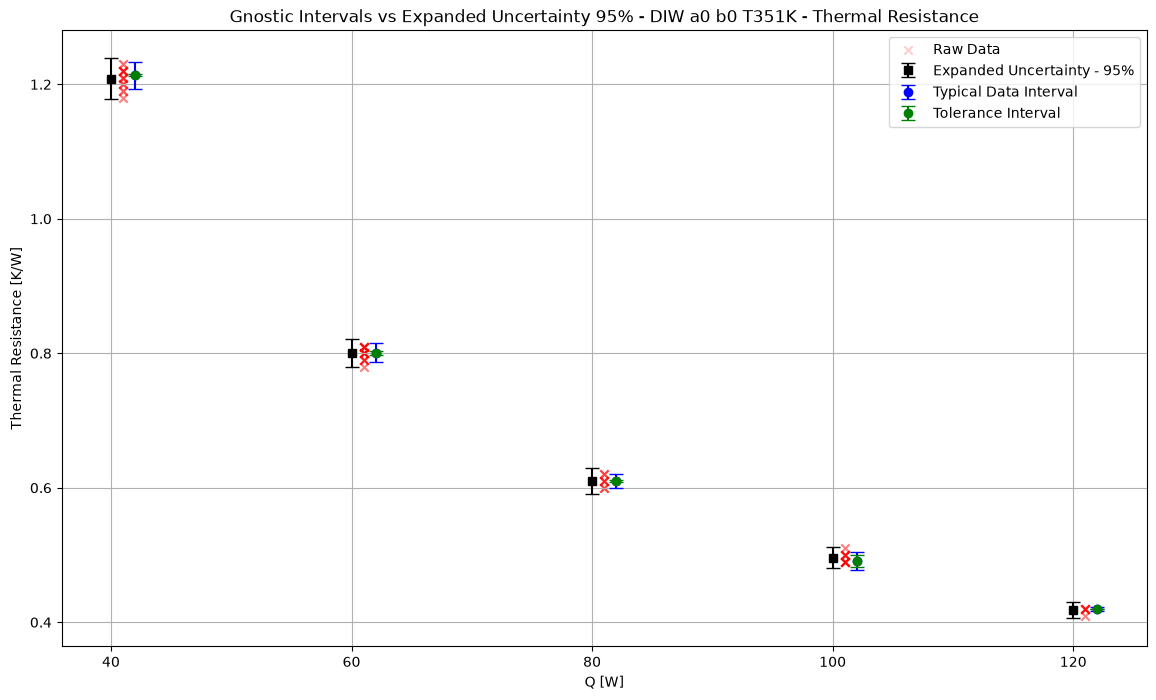

In [56]:
# plot intervals, x axis Q and y axis gnostic interval. mean, tolerance interval and typical data interval
import matplotlib.pyplot as plt

Q_values = [40, 60, 80, 100, 120]
intervals = [intv_q40, intv_q60, intv_q80, intv_q100, intv_q120]

plt.figure(figsize=(14, 8))
plt.errorbar(Q_values, mean_values, yerr=expanded_uncertainties, fmt='s', capsize=5, label='Expanded Uncertainty - 95%', color='black')
offset = 2
offset_raw = 1
# 40Q
plt.errorbar(40+offset, intv_q40.item()['Z0'], 
             yerr=(intv_q40.item()['ZU'] - intv_q40.item()['ZL']),
             fmt='o', capsize=5, label='Typical Data Interval', color='blue')
plt.errorbar(40+offset, intv_q40.item()['Z0'], 
             yerr=(intv_q40.item()['Z0U'] - intv_q40.item()['Z0L']),
             fmt='o', capsize=5, label='Tolerance Interval', color='green')

# 60Q
plt.errorbar(60+offset, intv_q60.item()['Z0'], 
             yerr=(intv_q60.item()['ZU'] - intv_q60.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(60+offset, intv_q60.item()['Z0'], 
             yerr=(intv_q60.item()['Z0U'] - intv_q60.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 80Q
plt.errorbar(80+offset, intv_q80.item()['Z0'], 
             yerr=(intv_q80.item()['ZU'] - intv_q80.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(80+offset, intv_q80.item()['Z0'], 
             yerr=(intv_q80.item()['Z0U'] - intv_q80.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 100Q
plt.errorbar(100+offset, intv_q100.item()['Z0'], 
             yerr=(intv_q100.item()['ZU'] - intv_q100.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(100+offset, intv_q100.item()['Z0'], 
             yerr=(intv_q100.item()['Z0U'] - intv_q100.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# 120Q
plt.errorbar(120+offset, intv_q120.item()['Z0'], 
             yerr=(intv_q120.item()['ZU'] - intv_q120.item()['ZL']),
             fmt='o', capsize=5, color='blue')
plt.errorbar(120+offset, intv_q120.item()['Z0'], 
             yerr=(intv_q120.item()['Z0U'] - intv_q120.item()['Z0L']),
             fmt='o', capsize=5, color='green')

# raw data points for reference
plt.scatter([40+offset_raw]*len(df_Q40_DIW_a90_b0_T_TR), df_Q40_DIW_a90_b0_T_TR, color='red', alpha=0.2, label='Raw Data', marker='x')
plt.scatter([60+offset_raw]*len(df_Q60_DIW_a90_b0_T_TR), df_Q60_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([80+offset_raw]*len(df_Q80_DIW_a90_b0_T_TR), df_Q80_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([100+offset_raw]*len(df_Q100_DIW_a90_b0_T_TR), df_Q100_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.scatter([120+offset_raw]*len(df_Q120_DIW_a90_b0_T_TR), df_Q120_DIW_a90_b0_T_TR, color='red', alpha=0.5, marker='x')
plt.xlabel('Q [W]')
plt.ylabel('Thermal Resistance [K/W]')
plt.legend()
plt.grid()
plt.title(f'Gnostic Intervals vs Expanded Uncertainty 95% - DIW a{alpha} b0 T{t}K - Thermal Resistance')
plt.show()

# Intervals Summary Table

In [53]:
# table consisteing 95%EU with mean + gnostic mean (Z0) and tolerance intervals and typical data intervals

import pandas as pd
data = {
    'Q': [40, 60, 80, 100, 120],
    'alpha': [0, 0, 0, 0, 0],
    'mean stat': [mean_Q40, mean_Q60, mean_Q80, mean_Q100, mean_Q120],
    'EU 95': [expanded_Q40, expanded_Q60, expanded_Q80, expanded_Q100, expanded_Q120],
    'mean mg': [intv_q40.item()['Z0'], intv_q60.item()['Z0'], intv_q80.item()['Z0'], intv_q100.item()['Z0'], intv_q120.item()['Z0']],
    'Z0L': [intv_q40.item()['Z0L'], intv_q60.item()['Z0L'], intv_q80.item()['Z0L'], intv_q100.item()['Z0L'], intv_q120.item()['Z0L']],
    'Z0U': [intv_q40.item()['Z0U'], intv_q60.item()['Z0U'], intv_q80.item()['Z0U'], intv_q100.item()['Z0U'], intv_q120.item()['Z0U']],
    'ZL': [intv_q40.item()['ZL'], intv_q60.item()['ZL'], intv_q80.item()['ZL'], intv_q100.item()['ZL'], intv_q120.item()['ZL']],
    'ZU': [intv_q40.item()['ZU'], intv_q60.item()['ZU'], intv_q80.item()['ZU'], intv_q100.item()['ZU'], intv_q120.item()['ZU']]
}
df_intervals = pd.DataFrame(data)

# save df
df_intervals.to_csv("df_intervals_a0.csv", index=False)

In [54]:
df_intervals

,Q,alpha,mean stat,EU 95,mean mg,Z0L,Z0U,ZL,ZU
0,40,0,1.208378,0.030049,1.21365,1.212698,1.214513,1.203146,1.223436
1,60,0,0.800000,0.020756,0.80103,0.799787,0.802822,0.794075,0.808532
2,80,0,0.610000,0.019979,0.61000,0.608942,0.611079,0.604810,0.615189
3,100,0,0.496000,0.015817,0.49106,0.490588,0.499841,0.487315,0.500310
4,120,0,0.418000,0.012417,0.41998,0.419875,0.420145,0.418487,0.421086
